In [1]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rc('xtick', direction='in', top=True)
mpl.rc('ytick', direction='in', right=True)
mpl.rc('xtick.minor', visible=True)
mpl.rc('ytick.minor', visible=True)
import os
import json
rng = np.random.default_rng()


# Load Model

In [81]:
import torch
import torch.nn as nn
import joblib

class PeakTransformer(nn.Module):
    def __init__(
        self,
        n_features,
        n_classes,
        d_model,
        n_heads,
        n_layers,
        dim_feedforward,
        dropout
    ):
        super().__init__()

        self.input_proj = nn.Linear(n_features, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        self.classifier = nn.Linear(d_model, n_classes)

    def forward(self, x):
        x = self.input_proj(x)
        x = self.encoder(x)
        logits = self.classifier(x)
        return logits


# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths
model_path = "Trained_models/7_feat_SNR10_doubleRule_transformer.pt"
scaler_path = "Trained_models/7_feat_SNR10_doubleRule_scaler.pkl"

# Load checkpoint
checkpoint = torch.load(
    model_path,
    map_location=device
)

# Build model using saved architecture parameters
model = PeakTransformer(
    n_features=checkpoint["n_features"],
    n_classes=checkpoint["n_classes"],
    d_model=checkpoint["d_model"],
    n_heads=checkpoint["n_heads"],
    n_layers=checkpoint["n_layers"],
    dim_feedforward=checkpoint["dim_feedforward"],
    dropout=checkpoint["dropout"]
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])

model.eval()


scaler = joblib.load(scaler_path)

In [82]:
label_to_class = {
    -2: 0,
    -1: 1,
     0: 2,
     1: 3,
     2: 4,
}

class_to_label = {
    0: -2,
    1: -1,
    2: 0,
    3: 1,
    4: 2,
    5: np.inf,
}

def band_encoding(outputs):
    outputs_incoded =np.empty(outputs.shape,dtype=np.int64)

    outputs_incoded[outputs == -2] = 0
    outputs_incoded[outputs == -1] = 1
    outputs_incoded[outputs ==  0] = 2
    outputs_incoded[outputs ==  1] = 3
    outputs_incoded[outputs ==  2] = 4
    outputs_incoded[np.isinf(outputs)] = 5

    return outputs_incoded

# Load testing data

In [3]:
base_path1="testing_data/TE011results"
index_path1 = os.path.join(base_path1, "Te011.json")
with open(index_path1, "r") as f:
    TE011Testing_Index = json.load(f)

In [4]:
base_path2="testing_data/TE012results"
index_path2 = os.path.join(base_path2, "Te012.json")
with open(index_path2, "r") as f:
    TE012Testing_Index = json.load(f)

# Noise and Band loading

In [5]:
def more_feature_inputs_outputs(index1,index2,spread=9,noise=False,SNR=1,verbose=False,minpeaks=True,freq_diff_features=False):
    """
    This Function takes 2 premade Jason indexes containing a file structure of the angle position and then histograms of a simulation data ROOT file
    The method to create these jason files can be found in data_load.ipynb within this same directory.

    Inputs

    Index1: the TE011 Jason index
    Index2: The TE012 Jason index

    spread=9 : this is used in several points it gneraly refers to the number of frequency bins arround a central point that can be considerd within the same peak or is likly to be that same peak
    Noise=False: When true adds noise to the PSDs based on an SNR from the highest peak
    SNR=1: said SNR
    verbose=False: if true prints an update on progress as the fuction runs
    minpeaks=True: When true will output 5 relvent peaks corisponding to the 5 posible sidebands when false will output 10 relivent peaks 5 from TE011 5 from TE012
    Freq_diff_features=False: adds features to the output of every frequenceas difference to every other frequency

    Outputs

    all_sidebands: a nx5x2 array of the location and power of each sideband in the order -2,0,2,-1,1

    Inputs_sorted: an array of the classifier inputs sorted by frequency npsds x nPeaks x nfeatures

    Outputs_sorted: an array of the classifier outputs npsd x nPeaks with labels -2,-1,0,1,2,np.inf corisponding to the input peak at the same locatin if it is a sideband with said lable or junk/noise np.inf


    """

    #Spread needs to be odd
    if spread % 2 != 1:
        spread += 1

    # arrays of the "locations" of sidebands
    band1 = np.array([-2, 0, 2,])
    band2 = np.array([-1,1])

    #preparing arrays
    all_sidebands = []
    all_maxbands = []
    all_outputs=[]


    jsn_name = "LocustEventProperties.json"

    #Begin iteration through angles the angles for Index1 and Index2 should be the same
    for angle in index1:

        #Begin iteration through position the angles for Index1 and Index2 should be the same
        for position in index1[angle]:

            #Progress printing
            if verbose:
                print(f"Sidebands:Processing angle={angle}, position={position}", flush=True)

            #loading relevent information from the event properties jason file
            jsn_info = index1[angle][position][jsn_name]
            jsn_filepath = jsn_info["filepath"]

            with open(jsn_filepath, "r") as f:
                jsn = json.load(f)
        
            avgax = jsn["0"]["0"]["avg-axial-frequency"]
            central = jsn["0"]["0"]["output-avg-frequency"]

            #Loading and storing all of the filepaths for each PSD
            psd_by_filepath1 = {}
            psd_by_filepath2 = {}

            for hist_name, hist_info in index1[angle][position].items():
                if "PSD" not in hist_name:
                    continue

                filepath = hist_info["filepath"]

                if filepath not in psd_by_filepath1:
                    psd_by_filepath1[filepath] = []

                psd_by_filepath1[filepath].append(hist_name)  
            
            for hist_name, hist_info in index2[angle][position].items():
                if "PSD" not in hist_name:
                    continue

                filepath = hist_info["filepath"]

                if filepath not in psd_by_filepath2:
                    psd_by_filepath2[filepath] = []

                psd_by_filepath2[filepath].append(hist_name)

            # Begin Itteration through each file

            for (filepath1, hist_names), (filepath2, _) in zip(psd_by_filepath1.items(), psd_by_filepath2.items()):
                file1 = ROOT.TFile.Open(filepath1)
                file2 = ROOT.TFile.Open(filepath2)
                if not file1 or file1.IsZombie():
                    raise RuntimeError(f"Could not open ROOT file: {filepath}")
                if not file2 or file2.IsZombie():
                    raise RuntimeError(f"Could not open ROOT file: {filepath}")
                try:
                    # Begin Itteration through each Hist

                    for hist_name in hist_names:
                        hist1 = file1.Get(hist_name)
                        hist2 = file2.Get(hist_name)
                        if not hist1 or not hist2:
                            raise RuntimeError(
                                f"Missing histogram {hist_name} in file {filepath}"
                            )
                        nbins = hist1.GetNbinsX()
                        
                        bins = range(1, nbins + 1)

                        #Loading powers and frequencies from both Hists
                        power1 = []
                        power2 = []
                        center1 = []
                        center2 = []

                        for i in bins:
                            power1.append(hist1.GetBinContent(i))
                            power2.append(hist2.GetBinContent(i))
                            center = hist1.GetBinCenter(i)
                            center1.append(center)
                            center2.append(center)

                        power1 = np.array(power1)
                        power2 = np.array(power2)
                        center1 = np.array(center1)
                        center2 = np.array(center2)

                        space1=np.mean(np.diff(center1))
                        space2=np.mean(np.diff(center2))
                        
                        # Finding and storing the Location and Power of each sideband -2,0,2 from TE011 and -1,1 from TE012

                        sidebands=[]

                        for band in band1:

                            target = central + (avgax * band)
                            mask = np.abs(center1 - target) <= (space1 * spread)

                            if np.any(mask):

                                local_idx = np.argmax(power1[mask])
                                max_idx = np.where(mask)[0][local_idx]
                                power = power1[max_idx]

                                if power == 0:
                                    loc = np.inf
                                    pos=0
                                else:
                                    loc = int(band)
                                    pos=center1[max_idx]

                                result = (power,pos, loc)
                            else:
                                result = (0, 0, np.inf)
                                
                            sidebands.append(result)

                        for band in band2:

                            target = central + (avgax * band)
                            mask = np.abs(center2 - target) <= (space2 * spread)

                            if np.any(mask):
 
                                local_idx = np.argmax(power2[mask])
                                max_idx = np.where(mask)[0][local_idx]
                                power = power2[max_idx]

                                if power == 0:
                                    loc = np.inf
                                    pos=0
                                else:
                                    loc = int(band)
                                    pos=center2[max_idx]

                                result = (power,pos, loc)
                            else:
                                result = (0, 0, np.inf)

                            sidebands.append(result)
                            
                            
                        sidebands = np.array(sidebands)


                        #Finding and loading all relevent maximum peaks for inputs

                        maxbands1=[]
                        maxbands2=[]
                        power_sim1 = power1.copy()
                        power_sim2 = power2.copy()

                        #Adding Noise  
                        if noise:
                            mx1=np.max(power_sim1)
                            mx2=np.max(power_sim2)
                            sigma1=np.sqrt(mx1/(2*SNR))
                            sigma2=np.sqrt(mx2/(2*SNR))
                            noise_power1 = np.abs(np.random.normal(0, sigma1, nbins) + 1j*np.random.normal(0, sigma1, nbins))**2
                            noise_power2 = np.abs(np.random.normal(0, sigma2, nbins) + 1j*np.random.normal(0, sigma2, nbins))**2
                            
                            power_sim1+=noise_power1
                            power_sim2+=noise_power2

                        max_peaks_found1=0 
                        max_peaks_found2=0 

                        if minpeaks:
                            maxpeaks1=3
                            maxpeaks2=2
                        else:
                            maxpeaks1=5
                            maxpeaks2=5

                        while max_peaks_found1<maxpeaks1:

                            mx=np.argmax(power_sim1)
                            center=float(center1[mx]) 
                            power=float(power_sim1[mx])

                            if len(maxbands1) > 0:
                                matches = np.where(
                                    np.abs(np.array(maxbands1)[:,1] - center) <= space1 * spread)[0]
                            else:
                                matches = []

                            if len(matches) == 1 and power !=0 :
                                maxbands1[matches[0]][0]+=power
                            else:
                                maxbands1.append([power,center])
                                max_peaks_found1+=1
                            
                            power_sim1[mx] = 0
                            
                        while max_peaks_found2<maxpeaks2:

                            mx=np.argmax(power_sim2)
                            center=float(center2[mx]) 
                            power=float(power_sim2[mx])

                            if len(maxbands2) > 0:
                                matches = np.where(
                                    np.abs(np.array(maxbands2)[:,1] - center) <= space2 * spread)[0]
                            else:
                                matches = []

                            if len(matches) == 1 and power !=0 :
                                maxbands2[matches[0]][0]+=power
                            else:
                                maxbands2.append([power,center])
                                max_peaks_found2+=1

                            power_sim2[mx] = 0

                        maxbands1=np.array(maxbands1)
                        maxbands2=np.array(maxbands2)
                        
                        maxbands1_sorted = maxbands1[np.argsort(maxbands1[:, 1])]
                        maxbands2_sorted = maxbands2[np.argsort(maxbands2[:, 1])]

                        maxbands = np.vstack((maxbands1_sorted, maxbands2_sorted))

                        # Creating outputs by coparing sidebands and maxbands to find matching peaks

                        ar1=maxbands
                        ar2=sidebands
                        match_matrix = np.isclose(ar1[:, None, 1],ar2[None, :, 1],rtol=0,atol=1e-6)
                        ar1_i, ar2_i = np.where(match_matrix)
                        out = np.full(ar1.shape[0], np.inf)
                        out[ar1_i] = ar2[ar2_i, 2]
                        if minpeaks:
                        
                            out[:3][np.isin(out[:3], [-1, 1])] = np.inf
                            out[3:][np.isin(out[3:], [-2, 0, 2])] = np.inf
                        else:
                
                            out[:5][np.isin(out[:5], [-1, 1])] = np.inf
                            out[5:][np.isin(out[5:], [-2, 0, 2])] = np.inf
                        
                        sort_idx = np.argsort(maxbands[:, 1])
                        maxbands_sorted = maxbands[sort_idx]
                        out_out=out[sort_idx]
                        sidebands_out=sidebands[np.argsort(sidebands[:,1])]

                        # Adding Frequnecy Difference features if requensted
                        if freq_diff_features:

                            freq = maxbands_sorted[:, 1]
                            diffs = freq[:, None] - freq[None, :]  

                            maxbands_sorted = np.hstack((maxbands_sorted, diffs))
                            maxbands_out=maxbands_sorted

                        else:
                            maxbands_out=maxbands_sorted


                        

                        all_sidebands.append(sidebands_out)
                        all_maxbands.append(maxbands_out)
                        all_outputs.append(out_out)
                finally:
                    file1.Close()
                    file2.Close()
    all_sidebands=np.array(all_sidebands)
    all_maxbands=np.array(all_maxbands)
    all_outputs=np.array(all_outputs)

    return(all_sidebands,all_maxbands,all_outputs)

# Test array loading


In [32]:
sidebands,Testing_inputs,Testing_Outputs=more_feature_inputs_outputs(TE011Testing_Index,TE012Testing_Index,freq_diff_features=True,noise=True,SNR=100)

# Model Testing Functions

In [6]:
def classify_one_psd(model, single_psd, scaler, device):
    """
    single_psd shape: (10, 2)

    Returns:
        predicted_classes : (10,) integer classes (0-5)
        confidences       : (10,) probability of the predicted class
    """

    model.eval()

    # Scale features
    single_scaled = scaler.transform(single_psd)

    # Add batch dimension
    X = torch.tensor(
        single_scaled,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(X)
        probabilities = torch.softmax(logits, dim=-1)

    # Remove batch dimension
    probabilities = probabilities.squeeze(0)

    # Most likely class for each peak
    predicted_classes = torch.argmax(probabilities, dim=1)

    # Probability of the predicted class
    confidences = probabilities.gather(
        1,
        predicted_classes.unsqueeze(1)
    ).squeeze(1)

    predicted_classes=predicted_classes.cpu().numpy()

    predicted_labels = np.array([
        class_to_label[c] for c in predicted_classes
    ])

    return predicted_labels, confidences.cpu().numpy()

def model_acuracy(testing_inputs,testing_outputs,model,scaler,device,remove_doubles=False,cutoff=0,prnt=0):
    empt=[]
    total_PSDs=testing_inputs.shape[0]
    used_PSDs=total_PSDs
    junk=0
    for i in range(total_PSDs):
        prediction,confidence=classify_one_psd(model,testing_inputs[i],scaler,device)
        sim=np.mean(prediction==testing_outputs[i])
        values, counts = np.unique(prediction, return_counts=True)
        cut=np.any(confidence<cutoff)
        is_double=not np.all(counts[values != np.inf] == 1)

        if prnt == 1:
            if sim!=1:
                print(prediction,testing_outputs[i],confidence,i)
        elif prnt==2:
            if is_double:
                print(prediction,testing_outputs[i],confidence)
        elif prnt ==3:
            if cut:
                print(prediction,testing_outputs[i],confidence)
    
        if np.all(prediction == np.inf):
            junk=junk+1
        if remove_doubles:
            double=is_double
        else:
            double=remove_doubles
        
        if cut or double:
            used_PSDs-=1
        else:
            empt.append(sim)

    acc=np.mean(empt)
    size=used_PSDs/total_PSDs
    jnk=junk/total_PSDs
    return(acc,size,jnk)

In [7]:
def test_noise(index1,index2,noise_array,model,scaler,device):
    accuarcy = np.zeros(len(noise_array), dtype=float)
    full_size = np.zeros(len(noise_array), dtype=float)
    full_junk = np.zeros(len(noise_array), dtype=float)

    for i in range(len(noise_array)):
        print(noise_array[i])
        sidebands,Testing_inputs,Testing_Outputs=more_feature_inputs_outputs(TE011Testing_Index,TE012Testing_Index,freq_diff_features=True,noise=True,SNR=noise_array[i])
        acc,size,junk=model_acuracy(Testing_inputs,Testing_Outputs,model,scaler,device)
        accuarcy[i]=acc
        full_size[i]=size
        full_junk[i]=junk

    return(accuarcy,full_size,full_junk)




# Model Testing Run

In [19]:
noiserng1=np.arange(10,105,5)
print(noiserng1)
noiserng2=np.arange(1,10,1)
print(noiserng2)

noiserng=np.hstack((noiserng2,noiserng1))
print(noiserng)

[ 10  15  20  25  30  35  40  45  50  55  60  65  70  75  80  85  90  95
 100]
[1 2 3 4 5 6 7 8 9]
[  1   2   3   4   5   6   7   8   9  10  15  20  25  30  35  40  45  50
  55  60  65  70  75  80  85  90  95 100]


In [20]:
sidenioise=[]
innoise=[]
outnoise=[]
for i in range(len(noiserng)):
    print(noiserng[i])
    sidebands,Testing_inputs,Testing_Outputs=more_feature_inputs_outputs(TE011Testing_Index,TE012Testing_Index,freq_diff_features=True,noise=True,SNR=noiserng[i])
    sidenioise.append(sidebands)
    innoise.append(Testing_inputs)
    outnoise.append(Testing_Outputs)

1
2
3
4
5
6
7
8
9
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


In [83]:
accuarcy = np.zeros(len(noiserng), dtype=float)
full_size = np.zeros(len(noiserng), dtype=float)
full_junk = np.zeros(len(noiserng), dtype=float)

for i in range(len(noiserng)):
    print(noiserng[i])
    acc,size,junk=model_acuracy(innoise[i],outnoise[i],model,scaler,device)
    accuarcy[i]=acc
    full_size[i]=size
    full_junk[i]=junk



1
2
3
4
5
6
7
8
9
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


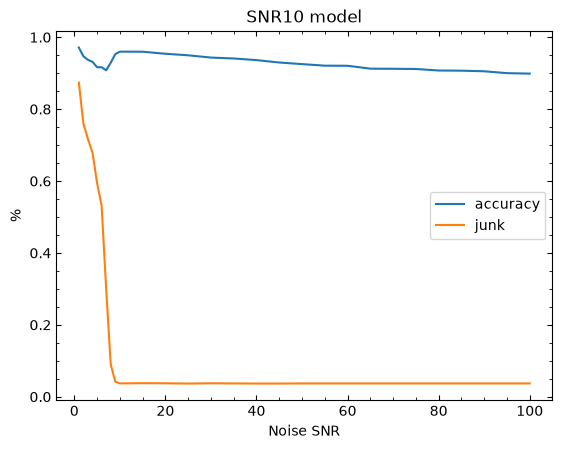

In [84]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(noiserng,accuarcy,label='accuracy')
# ax.plot(noiserng,full_size,label='size')
ax.plot(noiserng,full_junk,label='junk')
ax.set_ylabel('%')
ax.set_xlabel('Noise SNR')
ax.set_title('SNR10 model')
ax.legend()

In [73]:
pt=10
acc,size,junk=model_acuracy(innoise[(np.where(noiserng==pt)[0][0])],outnoise[(np.where(noiserng==pt)[0][0])],model,scaler,device,prnt=1)


[inf -2. inf inf inf] [inf -2.  1. inf inf] [0.99945587 0.986033   0.87796456 0.9994746  0.9993161 ] 52
[-2.  0.  2. inf inf] [-2. inf  1. inf inf] [0.5374235  0.500997   0.57161784 0.9994011  0.9994012 ] 55
[inf -2.  0.  1. inf] [inf -2. inf inf inf] [0.9981838 0.9309375 0.7209041 0.8262009 0.9994491] 58
[inf  0.  1. inf inf] [inf -2. inf  1. inf] [0.9994388  0.7684299  0.84822804 0.9140173  0.9992111 ] 59
[inf -2.  0.  1. inf] [inf -2. inf  1. inf] [0.9994469  0.85845566 0.5739591  0.87928766 0.9993381 ] 60
[inf inf -2.  0.  1.] [inf inf -2. inf  1.] [0.9992489  0.9904807  0.95488244 0.9057634  0.93725026] 71
[-2. inf inf inf inf] [-2.  1. inf inf inf] [0.99438137 0.48618427 0.9971826  0.999405   0.99939   ] 73
[inf inf -2. inf inf] [inf inf -2.  1. inf] [0.9994679  0.9994785  0.7963963  0.96042025 0.9990159 ] 74
[-2. inf inf  1. inf] [-2. inf  0.  1. inf] [0.85055304 0.55045587 0.78464395 0.3974773  0.99914813] 76
[inf inf -2. inf inf] [inf inf -2.  1. inf] [0.99947757 0.99945945 0.

In [74]:
print(acc)

0.9571851851851852
